# DPoP Replay-State Durability — Reproducible Research Report

Notebook laporan analisis; **tidak menjalankan eksperimen dan tidak mengubah raw data**.

### Tujuan
- Membaca summary CSV keluaran `scripts/analyze.py`.
- Audit artefak validasi dan dataset.
- Menampilkan metrik keamanan, durability, first-use correctness, dan latency.
- Memperlakukan experiment repetition/run sebagai unit analisis; request individual bukan observasi independen.

### Menjalankan
Buka dari root repository, pilih kernel environment proyek, lalu **Run All**. Notebook tidak melakukan `pip install`. Jika auto-discovery salah, tetapkan path pada bagian Configuration.

## 1. Project discovery
Menemukan repository berdasarkan struktur folder; tidak mengubah working directory.

In [5]:
from pathlib import Path
import os, sys, json, csv, math
from datetime import datetime

PROJECT_ROOT = None  # Optional override: Path("/absolute/path/to/repository")

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "research" / "dpop-durability").exists() or (
            (p / "results" / "dpop-durability").exists() and (p / "scripts").exists()
        ):
            return p
    raise FileNotFoundError("Root repository tidak ditemukan. Set PROJECT_ROOT secara manual.")

if PROJECT_ROOT is None:
    PROJECT_ROOT = find_project_root()
PROJECT_ROOT = Path(PROJECT_ROOT).resolve()
RESULTS_ROOT = PROJECT_ROOT / "results" / "dpop-durability"
print("Project root:", PROJECT_ROOT)
print("Results root:", RESULTS_ROOT)
print("Python:", sys.version.split()[0])

Project root: /home/nasyikhqusyairy/Projects/repositories/mse
Results root: /home/nasyikhqusyairy/Projects/repositories/mse/results/dpop-durability
Python: 3.14.4


## 2. Configuration

Auto-discovery memilih summary paling baru berdasarkan modification time. Untuk analisis final/publikasi, **kunci path secara eksplisit** agar pemilihan data dapat direproduksi.

In [6]:
SUMMARY_FILE = None  # Optional explicit Path to summaries/results-table.csv
DATASET_DIRS = None  # Optional explicit list of dataset/run directories

def newest_file(paths):
    paths = [Path(p) for p in paths if Path(p).is_file()]
    return max(paths, key=lambda p: p.stat().st_mtime) if paths else None

if SUMMARY_FILE is None:
    SUMMARY_FILE = newest_file(RESULTS_ROOT.glob("**/summaries/results-table.csv")) if RESULTS_ROOT.exists() else None
else:
    SUMMARY_FILE = Path(SUMMARY_FILE)

if SUMMARY_FILE is None:
    raise FileNotFoundError(f"results-table.csv tidak ditemukan di {RESULTS_ROOT}; jalankan analyzer atau set SUMMARY_FILE.")

if DATASET_DIRS is None:
    DATASET_DIRS = sorted({p.parent.parent for p in RESULTS_ROOT.glob("**/validation/validation-summary.json")}) if RESULTS_ROOT.exists() else []
else:
    DATASET_DIRS = [Path(p) for p in DATASET_DIRS]

print("Selected summary:", SUMMARY_FILE)
print("Dataset dirs:", len(DATASET_DIRS))
for p in DATASET_DIRS: print(" -", p)

Selected summary: /home/nasyikhqusyairy/Projects/repositories/mse/results/dpop-durability/dpop-2026-11-19T07-46-29-011Z-55d0f618/summaries/results-table.csv
Dataset dirs: 7
 - /home/nasyikhqusyairy/Projects/repositories/mse/results/dpop-durability/dpop-2026-11-19T07-46-29-011Z-55d0f618
 - /home/nasyikhqusyairy/Projects/repositories/mse/results/dpop-durability/dpop-2026-11-19T07-49-40-957Z-d36a3dee
 - /home/nasyikhqusyairy/Projects/repositories/mse/results/dpop-durability/dpop-2026-11-19T08-58-39-444Z-145889a3
 - /home/nasyikhqusyairy/Projects/repositories/mse/results/dpop-durability/dpop-repl-2026-11-19T08-03-05-644Z-a8b2f011
 - /home/nasyikhqusyairy/Projects/repositories/mse/results/dpop-durability/dpop-repl-2026-11-19T08-14-59-904Z-e3af2e9c
 - /home/nasyikhqusyairy/Projects/repositories/mse/results/dpop-durability/dpop-repl-2026-11-19T08-16-16-028Z-a10c2e92
 - /home/nasyikhqusyairy/Projects/repositories/mse/results/dpop-durability/dpop-repl-2026-11-19T08-58-50-986Z-06ce64bd


## 3. Load summary & schema
Kolom dan nilai berasal langsung dari analyzer; notebook tidak menulis ulang metrik.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

summary_df = pd.read_csv(SUMMARY_FILE)
print(f"{len(summary_df)} rows × {len(summary_df.columns)} columns")
display(summary_df)
display(pd.DataFrame({"column": summary_df.columns,
                      "dtype": [str(t) for t in summary_df.dtypes],
                      "missing": [int(summary_df[c].isna().sum()) for c in summary_df.columns]}))

8 rows × 17 columns


,scenario,backend,independent_repetitions,replay_attempts,replay_acceptances,replay_acceptance_rate,wilson95_low,wilson95_high,replay_detections,acknowledged_write_losses,duplicate_protected_operations,valid_first_uses_accepted,valid_first_use_success_rate,latency_observations,latency_p50_ms,latency_p95_ms,latency_p99_ms
0,memory_normal,memory,15,15,0,0.0,0.000000,0.203889,15,0,0,15,1.0,30,0.524717,2.094163,3.157870
1,memory_process_restart,memory,15,15,15,1.0,0.796111,1.000000,0,0,15,15,1.0,30,0.435898,0.864968,1.012202
2,redis_normal_cross_instance,redis,15,15,0,0.0,0.000000,0.203889,15,0,0,15,1.0,30,0.674974,1.617811,1.831695
3,redis_primary_sigkill,redis,15,15,15,1.0,0.796111,1.000000,0,15,15,15,1.0,30,0.793726,2.250850,2.408825
4,primary_only_detached,primary_only_detached,10,10,10,1.0,0.722460,1.000000,0,10,10,10,1.0,20,0.831935,1.633508,2.438128
5,wait_replica_acked,wait_replica_acked,10,10,0,0.0,0.000000,0.277540,10,0,0,10,1.0,20,1.106680,2.048581,3.152347
6,wait_ack_insufficient,wait_ack_insufficient,10,10,10,1.0,0.722460,1.000000,0,0,0,0,0.0,20,126.743989,336.681172,337.147616
7,waitaof_local_replica_acked,waitaof_local_replica_acked,10,10,0,0.0,0.000000,0.277540,10,0,0,10,1.0,20,11.212872,208.071995,245.242302


,column,dtype,missing
0,scenario,str,0
1,backend,str,0
2,independent_repetitions,int64,0
3,replay_attempts,int64,0
4,replay_acceptances,int64,0
5,replay_acceptance_rate,float64,0
6,wilson95_low,float64,0
7,wilson95_high,float64,0
8,replay_detections,int64,0
9,acknowledged_write_losses,int64,0


## 4. Dataset artifact audit

Audit deskriptif file dan validation summary. Jumlah request bukan jumlah observasi independen untuk inferensi.

In [8]:
audit_rows = []
for d in DATASET_DIRS:
    d = Path(d)
    vp, rp, ep = d/"validation/validation-summary.json", d/"raw/requests.csv", d/"raw/events.jsonl"
    row = {"dataset": d.name, "directory_exists": d.exists(),
           "validation_summary_exists": vp.exists(), "requests_csv_exists": rp.exists(),
           "events_jsonl_exists": ep.exists(), "request_rows": None,
           "valid_experiment_runs": None, "validation_status": None, "error": None}
    if vp.exists():
        try:
            v = json.loads(vp.read_text())
            row["valid_experiment_runs"] = v.get("valid_experiment_runs")
            row["validation_status"] = v.get("status", v.get("valid", "not specified"))
        except Exception as e: row["error"] = "validation: " + repr(e)
    if rp.exists():
        try: row["request_rows"] = max(0, sum(1 for _ in rp.open(encoding="utf-8"))-1)
        except Exception as e: row["error"] = (row["error"] or "") + " requests: " + repr(e)
    audit_rows.append(row)
audit_df = pd.DataFrame(audit_rows)
display(audit_df)

,dataset,directory_exists,validation_summary_exists,requests_csv_exists,events_jsonl_exists,request_rows,valid_experiment_runs,validation_status,error
0,dpop-2026-11-19T07-46-29-011Z-55d0f618,True,True,True,True,40,5,not specified,None
1,dpop-2026-11-19T07-49-40-957Z-d36a3dee,True,True,True,True,40,5,not specified,None
2,dpop-2026-11-19T08-58-39-444Z-145889a3,True,True,True,True,40,5,not specified,None
3,dpop-repl-2026-11-19T08-03-05-644Z-a8b2f011,True,True,True,True,40,3,not specified,None
4,dpop-repl-2026-11-19T08-14-59-904Z-e3af2e9c,True,True,True,True,8,4,not specified,None
5,dpop-repl-2026-11-19T08-16-16-028Z-a10c2e92,True,True,True,True,40,5,not specified,None
6,dpop-repl-2026-11-19T08-58-50-986Z-06ce64bd,True,True,True,True,40,5,not specified,None


## 5. Security outcomes

Replay acceptance rate. Wilson 95% interval dihitung hanya jika numerator dan denominator tersedia di summary.

In [9]:
def first_col(df, candidates):
    return next((c for c in candidates if c in df.columns), None)
def num(x):
    try:
        if pd.isna(x): return None
        return float(x)
    except (TypeError, ValueError): return None
def wilson(k, n, z=1.959963984540054):
    if n <= 0: return (None, None)
    p=k/n; den=1+z*z/n
    center=(p+z*z/(2*n))/den
    half=z*math.sqrt((p*(1-p)+z*z/(4*n))/n)/den
    return max(0,center-half), min(1,center+half)

scenario_col=first_col(summary_df, ["scenario","condition","configuration"])
rate_col=first_col(summary_df, ["replay_acceptance_rate","replay_accept_rate"])
accepted_col=first_col(summary_df, ["replay_acceptances","replay_accepted","accepted_replays"])
attempt_col=first_col(summary_df, ["replay_attempts","replay_attempt_count"])
security_df=summary_df.copy()
if rate_col: security_df["replay_acceptance_rate_plot"]=pd.to_numeric(security_df[rate_col],errors="coerce")
if accepted_col and attempt_col:
    bounds=[]
    for _,r in security_df.iterrows():
        k,n=num(r[accepted_col]),num(r[attempt_col])
        bounds.append(wilson(int(k),int(n)) if k is not None and n and n>0 else (None,None))
    security_df["wilson95_lower"]=[x[0] for x in bounds]
    security_df["wilson95_upper"]=[x[1] for x in bounds]
display(security_df)

,scenario,backend,independent_repetitions,replay_attempts,replay_acceptances,replay_acceptance_rate,wilson95_low,wilson95_high,replay_detections,acknowledged_write_losses,duplicate_protected_operations,valid_first_uses_accepted,valid_first_use_success_rate,latency_observations,latency_p50_ms,latency_p95_ms,latency_p99_ms,replay_acceptance_rate_plot,wilson95_lower,wilson95_upper
0,memory_normal,memory,15,15,0,0.0,0.000000,0.203889,15,0,0,15,1.0,30,0.524717,2.094163,3.157870,0.0,0.000000,0.203883
1,memory_process_restart,memory,15,15,15,1.0,0.796111,1.000000,0,0,15,15,1.0,30,0.435898,0.864968,1.012202,1.0,0.796117,1.000000
2,redis_normal_cross_instance,redis,15,15,0,0.0,0.000000,0.203889,15,0,0,15,1.0,30,0.674974,1.617811,1.831695,0.0,0.000000,0.203883
3,redis_primary_sigkill,redis,15,15,15,1.0,0.796111,1.000000,0,15,15,15,1.0,30,0.793726,2.250850,2.408825,1.0,0.796117,1.000000
4,primary_only_detached,primary_only_detached,10,10,10,1.0,0.722460,1.000000,0,10,10,10,1.0,20,0.831935,1.633508,2.438128,1.0,0.722467,1.000000
5,wait_replica_acked,wait_replica_acked,10,10,0,0.0,0.000000,0.277540,10,0,0,10,1.0,20,1.106680,2.048581,3.152347,0.0,0.000000,0.277533
6,wait_ack_insufficient,wait_ack_insufficient,10,10,10,1.0,0.722460,1.000000,0,0,0,0,0.0,20,126.743989,336.681172,337.147616,1.0,0.722467,1.000000
7,waitaof_local_replica_acked,waitaof_local_replica_acked,10,10,0,0.0,0.000000,0.277540,10,0,0,10,1.0,20,11.212872,208.071995,245.242302,0.0,0.000000,0.277533


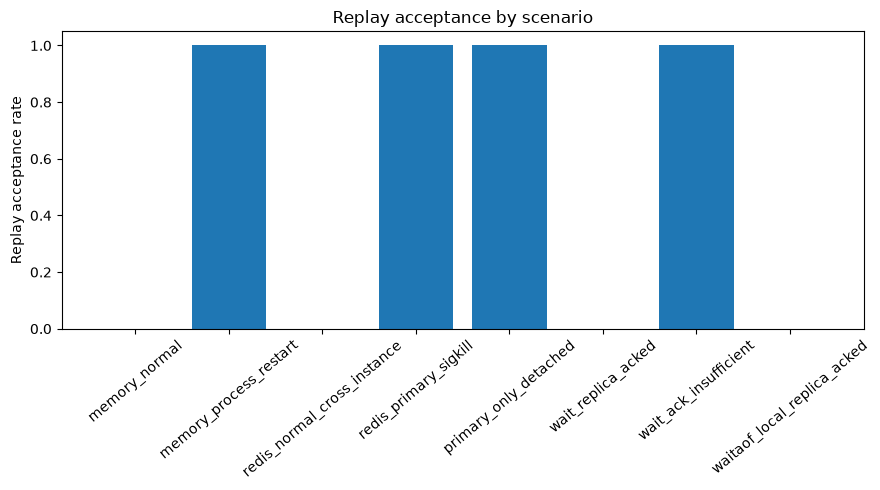

In [10]:
if scenario_col and rate_col:
    p=security_df.copy()
    p["rate"]=pd.to_numeric(p[rate_col],errors="coerce")
    p=p.dropna(subset=["rate"])
    fig,ax=plt.subplots(figsize=(max(9,len(p)*1.1),5))
    ax.bar(p[scenario_col].astype(str),p["rate"])
    ax.set_ylabel("Replay acceptance rate"); ax.set_ylim(0,1.05)
    ax.set_title("Replay acceptance by scenario"); ax.tick_params(axis="x",rotation=40)
    fig.tight_layout(); plt.show()
else:
    print("Plot dilewati: scenario/rate column tidak ditemukan.")

## 6. Durability, first-use, and availability indicators

Menampilkan kolom yang tersedia. **Request failure bukan otomatis acknowledged-write loss**; klaim harus didukung event timeline dan definisi validator.

In [11]:
metric_candidates=[
 "acknowledged_write_losses","ack_write_losses","acknowledged_write_loss_count",
 "duplicate_protected_operations","protected_operation_duplicates",
 "replay_detections","replay_detection_count",
 "valid_first_uses_accepted","first_use_success_rate",
 "successful_tasks","failed_tasks","availability_rate"
]
metrics=[c for c in metric_candidates if c in summary_df.columns]
display(summary_df[[c for c in ([scenario_col] if scenario_col else [])+metrics]])
if not metrics: print("Kolom kandidat tidak tersedia pada summary.")

,scenario,acknowledged_write_losses,duplicate_protected_operations,replay_detections,valid_first_uses_accepted
0,memory_normal,0,0,15,15
1,memory_process_restart,0,15,0,15
2,redis_normal_cross_instance,0,0,15,15
3,redis_primary_sigkill,15,15,0,15
4,primary_only_detached,10,10,0,10
5,wait_replica_acked,0,0,10,10
6,wait_ack_insufficient,0,0,0,0
7,waitaof_local_replica_acked,0,0,10,10


## 7. Latency

Percentile dilaporkan analyzer; visualisasi bersifat deskriptif. Untuk inferensi, gunakan nilai per repetition/run jika tersedia.

In [12]:
latency_cols=[c for c in summary_df.columns if any(t in c.lower() for t in ["latency","p50","p95","p99"])]
display(summary_df[[c for c in ([scenario_col] if scenario_col else [])+latency_cols]])
pcols=[c for c in summary_df.columns if c.lower() in {"p50_ms","p95_ms","p99_ms"}]
if scenario_col and pcols:
    plot_df=summary_df[[scenario_col]+pcols].copy()
    for c in pcols: plot_df[c]=pd.to_numeric(plot_df[c],errors="coerce")
    ax=plot_df.set_index(scenario_col)[pcols].plot(kind="bar",figsize=(max(9,len(plot_df)*1.1),5))
    ax.set_ylabel("Latency (ms)"); ax.set_title("Latency percentiles by scenario")
    ax.tick_params(axis="x",rotation=40); plt.tight_layout(); plt.show()
else: print("Latency plot dilewati: percentile standar tidak ditemukan.")

,scenario,latency_observations,latency_p50_ms,latency_p95_ms,latency_p99_ms
0,memory_normal,30,0.524717,2.094163,3.157870
1,memory_process_restart,30,0.435898,0.864968,1.012202
2,redis_normal_cross_instance,30,0.674974,1.617811,1.831695
3,redis_primary_sigkill,30,0.793726,2.250850,2.408825
4,primary_only_detached,20,0.831935,1.633508,2.438128
5,wait_replica_acked,20,1.106680,2.048581,3.152347
6,wait_ack_insufficient,20,126.743989,336.681172,337.147616
7,waitaof_local_replica_acked,20,11.212872,208.071995,245.242302


Latency plot dilewati: percentile standar tidak ditemukan.


## 8. Run-level detail (jika tersedia)

Jika summary memiliki identifier run/repetition, tampilkan urutan data. Summary agregat tanpa ID run tidak cukup untuk inferensi run-level.

In [13]:
run_col=first_col(summary_df,["run_id","experiment_run_id","repetition","replicate","rep"])
if run_col: display(summary_df.sort_values(run_col))
else: print("Tidak ada identifier repetition/run pada summary.")

Tidak ada identifier repetition/run pada summary.


## 9. Evidence checklist

Checklist interpretasi manual sebelum menulis hasil:

- [ ] Replay proof identik benar-benar diterima kembali?
- [ ] State yang hilang sebelumnya **telah acknowledged**?
- [ ] Timeline acknowledgement → fault → failover/recovery → replay dapat diaudit?
- [ ] First-use valid proof diterima? (memisahkan replay failure dari fail-closed/outage)
- [ ] Unit sample adalah independent repetitions, bukan request dalam satu run?
- [ ] Excluded runs memiliki alasan terdokumentasi dan raw data dipertahankan?
- [ ] Generalisasi dibatasi pada topology/configuration yang benar-benar diuji?

## 10. Scope & limitations

Jika eksperimen dilakukan pada satu host dengan dua Redis node dan manual promotion, hasil tidak membuktikan perilaku network partition, Sentinel, Redis Cluster, atau deployment multi-host. Jangan menggabungkan standalone dan replicated scenarios tanpa justifikasi desain.

## 11. Reproducibility record

Auto-discovery untuk eksplorasi; untuk final report set path secara eksplisit di Configuration.

In [14]:
repro_record={
 "analysis_timestamp_utc": datetime.utcnow().isoformat(timespec="seconds")+"Z",
 "project_root": str(PROJECT_ROOT),
 "summary_file": str(SUMMARY_FILE.resolve()),
 "summary_mtime": datetime.fromtimestamp(SUMMARY_FILE.stat().st_mtime).isoformat(),
 "dataset_dirs": [str(Path(p).resolve()) for p in DATASET_DIRS],
 "dataset_count": len(DATASET_DIRS),
 "summary_rows": int(len(summary_df)),
 "summary_columns": list(summary_df.columns),
}
display(pd.Series(repro_record,name="value").to_frame())

/tmp/ipykernel_613292/875420533.py:2: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "analysis_timestamp_utc": datetime.utcnow().isoformat(timespec="seconds")+"Z",


,value
analysis_timestamp_utc,2026-11-19T09:18:51Z
project_root,/home/nasyikhqusyairy/Projects/repositories/mse
summary_file,/home/nasyikhqusyairy/Projects/repositories/ms...
summary_mtime,2026-11-19T16:06:25.315971
dataset_dirs,[/home/nasyikhqusyairy/Projects/repositories/m...
dataset_count,7
summary_rows,8
summary_columns,"[scenario, backend, independent_repetitions, r..."
